# Stage 4, step 1: the silica dataset

**The question for stage 4.** For silica at SCAN accuracy, how much DFT data does each approach need,
and which one should the team invest in? Three contenders, trained on growing subsets of the same data:

1. SchNet from scratch: sees distances only (our lmax 0 picture), the "no equivariance" baseline.
2. MACE from scratch: equivariant, higher-order messages.
3. MACE-MP-0 fine-tuned: starts from the pretrained foundation model; the untouched model is the zero-data point.

The output will be one log-log plot: error against number of training structures, one line per approach.

**This notebook does not train anything.** It looks at the data, settles a few gotchas, and freezes the test set,
so every later model is judged on exactly the same structures.

Data: Erhard, Rohrer, Albe and Deringer, *A machine-learned interatomic potential for silica and its relation to
empirical models*, npj Comput. Mater. 2022. Zenodo record 6353684, CC-BY-4.0. 3,074 structures, SCAN functional (VASP).

In [1]:
import json, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ase.io import read, write
from ase.neighborlist import neighbor_list
from ase.visualize.plot import plot_atoms
from ase.geometry.rdf import get_rdf
from ase.stress import voigt_6_to_full_3x3_stress

DATA = Path("silica-benchmark/data/zenodo-6353684/sio2_potential_data/database/dataset.scan.2.xyz")
OUT = Path("silica-benchmark")
# reference categorical palette, first three slots (the all-pairs-safe set for scatter plots)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 110})

frames = read(DATA, index=":")
print(len(frames), "structures")

3074 structures


## 1. What is in the box

Every structure carries a `config_type` and most carry a `sub_simulation_type`. Together they give a "family":
the crystal phase name, or the melt-quench stage (liquid, quench, amorphous), or a cluster/dimer.

Note one ASE detail: recent ASE moves energy, forces and stress out of `atoms.info` into a calculator object,
so they are read from `atoms.calc.results`.

In [2]:
def family(a):
    ct, sub = a.info["config_type"], a.info.get("sub_simulation_type")
    if ct == "bulk_cryst":
        return sub
    if ct == "cluster":
        return {"O-O": "dimer O-O", "Si-O": "dimer Si-O", "Si-Si": "dimer Si-Si"}.get(sub, "small cluster")
    return {"bulk_amo": "amorphous"}.get(ct, ct)

AMU_A3_TO_GCC = 1.66054
rows = []
for i, a in enumerate(frames):
    r = a.calc.results
    f = np.linalg.norm(r["forces"], axis=1)
    rows.append(dict(
        idx=i, config_type=a.info["config_type"], family=family(a), natoms=len(a),
        e_per_atom=r["energy"] / len(a),
        density=a.get_masses().sum() * AMU_A3_TO_GCC / a.get_volume(),
        volume=a.get_volume(),
        f_mean=f.mean(), f_max=f.max(),
        pressure_gpa=-np.trace(r["stress"].reshape(3, 3) if r["stress"].size == 9 else np.diag(r["stress"][:3])) / 3 * 160.2177,
    ))
df = pd.DataFrame(rows)
summary = (df.groupby(["config_type", "family"])
             .agg(n=("idx", "size"), atoms=("natoms", "first"), total_atoms=("natoms", "sum"),
                  density_lo=("density", "min"), density_hi=("density", "max"))
             .round(2))
summary

n  atoms  total_atoms  density_lo  density_hi
config_type family                                                            
bulk_amo    amorphous          313    192        60096        2.00        3.00
bulk_cryst  Si-diamond         100      8          800        2.01        2.72
            beta_cristobalite  100     24         2400        1.89        2.55
            beta_quartz        100      9          900        2.20        2.97
            beta_tridymite     100     12         1200        1.89        2.55
            chabazite          200    108        21600        1.27        1.75
            coesite            200     48         9600        2.44        3.50
            low_cristobalite   200     12         2400        1.95        2.68
            low_quartz         200      9         1800        2.23        3.17
            low_tridymite      200    144        28800        1.92        2.68
            moganite           200     36         7200        2.20        2.98
            stishovite         200      6         1200        3.61        4.87
            tridymite_C2221    100     24         2400        1.91        2.58
            tridymite_P212121  100     72         7200        1.93        2.61
cluster     dimer O-O           41      2           82        0.01        0.01
            dimer Si-O          38      2           76        0.01        0.01
            dimer Si-Si         36      2           72        0.01        0.01
            small cluster       20      6          100        0.00        0.02
liquid      liquid             313    192        60096        2.00        3.00
quench      quench             313    192        60096        2.00        3.00

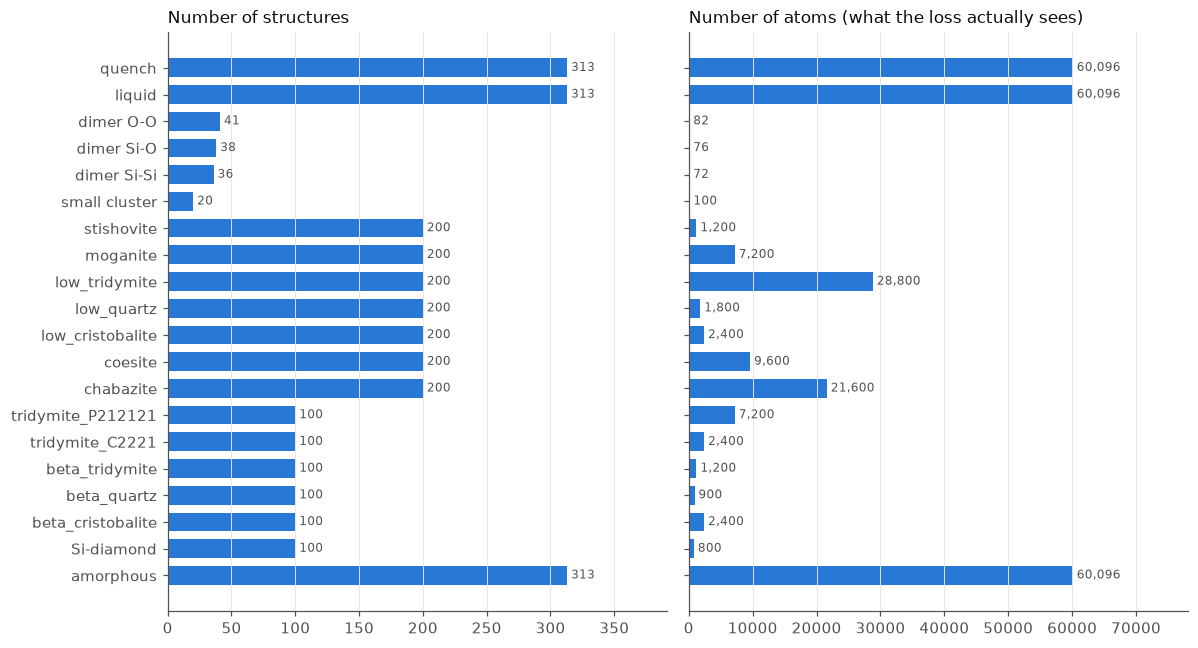

In [3]:
order = (df.groupby("family").agg(n=("idx", "size"), ct=("config_type", "first"), atoms=("natoms", "sum"))
           .sort_values(["ct", "n"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, col, title in [(axes[0], "n", "Number of structures"), (axes[1], "atoms", "Number of atoms (what the loss actually sees)")]:
    ax.barh(order.index, order[col], color=BLUE, height=0.7)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(order[col]):
        ax.text(v, y, f" {v:,}", va="center", fontsize=8, color=MUTED)
axes[0].set_xlim(0, order["n"].max() * 1.25); axes[1].set_xlim(0, order["atoms"].max() * 1.3)
plt.tight_layout(); plt.show()

**Read the two panels against each other.** By structure count the set looks crystal-heavy: 2,000 of 3,074 are crystals.
By atom count it flips. A crystal frame has 6 to 144 atoms (stishovite has only 6), while every liquid, quench
and amorphous frame has 192. Most of the force labels, which dominate training, come from the disordered structures.

This matters for the learning curve: "100 training structures" can mean 600 atoms or 19,000 atoms depending on what
was drawn. We will report both axes.

## 2. What the structures look like

A few representatives: two dense crystals, a porous zeolite, a glass from the melt-quench runs, and a dimer.

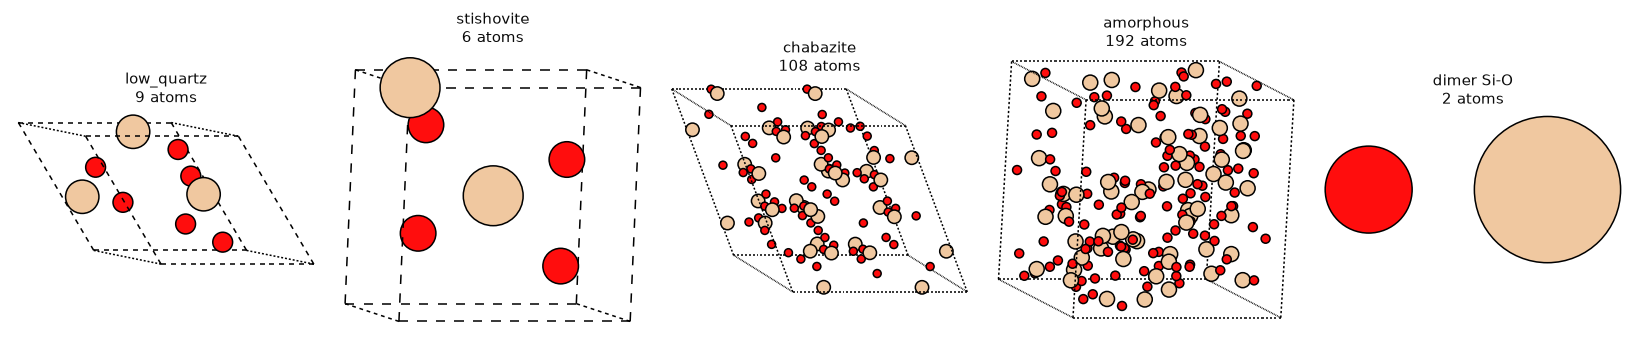

Si yellow-ish, O red (ASE jmol colours)


In [4]:
pick = ["low_quartz", "stishovite", "chabazite", "amorphous", "dimer Si-O"]
fig, axes = plt.subplots(1, len(pick), figsize=(15, 3.6))
for ax, fam in zip(axes, pick):
    a = frames[int(df[df.family == fam].iloc[0].idx)]
    plot_atoms(a, ax, radii=0.45, rotation="10x,20y,0z", show_unit_cell=2 if fam != "dimer Si-O" else 0)
    ax.set_title(f"{fam}\n{len(a)} atoms", fontsize=10, color=INK); ax.axis("off")
plt.tight_layout(); plt.show()
print("Si yellow-ish, O red (ASE jmol colours)")

## 3. A map of the dataset: density against energy

Each dot is one periodic structure. Low energy means stable; real quartz sits near 2.65 g/cc and real silica glass
near 2.20 g/cc. The crystals are deliberately squeezed and stretched around their own equilibrium (the horizontal
smears), and the melt-quench runs were done at fixed densities between 2.0 and 3.0 g/cc.

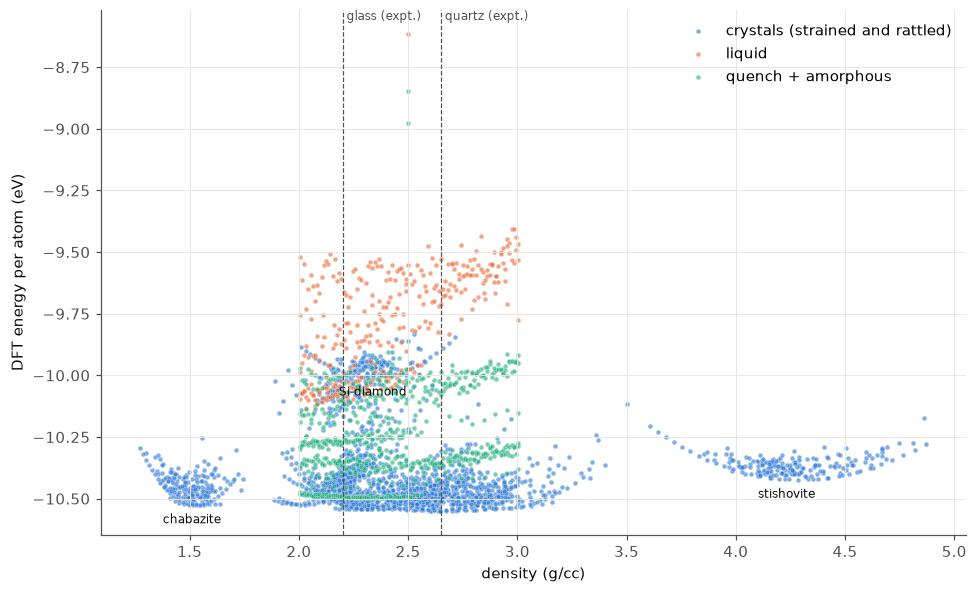

In [5]:
per = df[~df.config_type.eq("cluster")]
groups = [("crystals (strained and rattled)", per.config_type.eq("bulk_cryst"), BLUE),
          ("liquid", per.config_type.eq("liquid"), ORANGE),
          ("quench + amorphous", per.config_type.isin(["quench", "bulk_amo"]), AQUA)]
fig, ax = plt.subplots(figsize=(9, 5.5))
for name, m, c in groups:
    ax.scatter(per[m].density, per[m].e_per_atom, s=10, color=c, alpha=0.6, label=name, edgecolors="white", linewidths=0.3)
for fam in ["stishovite", "chabazite", "Si-diamond"]:
    s = per[per.family == fam]
    ax.annotate(fam, (s.density.median(), s.e_per_atom.min()), xytext=(0, -12), textcoords="offset points",
                ha="center", fontsize=8, color=INK)
for x, lab in [(2.65, "quartz (expt.)"), (2.20, "glass (expt.)")]:
    ax.axvline(x, color=MUTED, lw=0.8, ls="--"); ax.text(x, ax.get_ylim()[1], f" {lab}", fontsize=8, color=MUTED, va="top")
ax.set_xlabel("density (g/cc)"); ax.set_ylabel("DFT energy per atom (eV)")
ax.legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()

What to notice:

- The liquid band sits roughly 0.4 to 1 eV/atom above the crystals. The quench and amorphous frames fall in between,
  because a glass is "frozen liquid" that keeps some of that extra energy.
- Si-diamond (pure silicon, no oxygen) lands right inside the glass band on this map, even though it is a completely
  different material. Density and energy alone do not identify a structure; the model has to look at local environments.
  Si-diamond is there to teach it about Si-Si bonds, which appear in defective glasses.
- Stishovite at about 4.3 g/cc is the high-pressure phase where Si has 6 oxygen neighbours instead of 4.
  This is the "high-pressure structural transition" in the paper.

## 4. How big are the forces?

The force error is the main metric, so it helps to know what a "typical" force is in each part of the data.

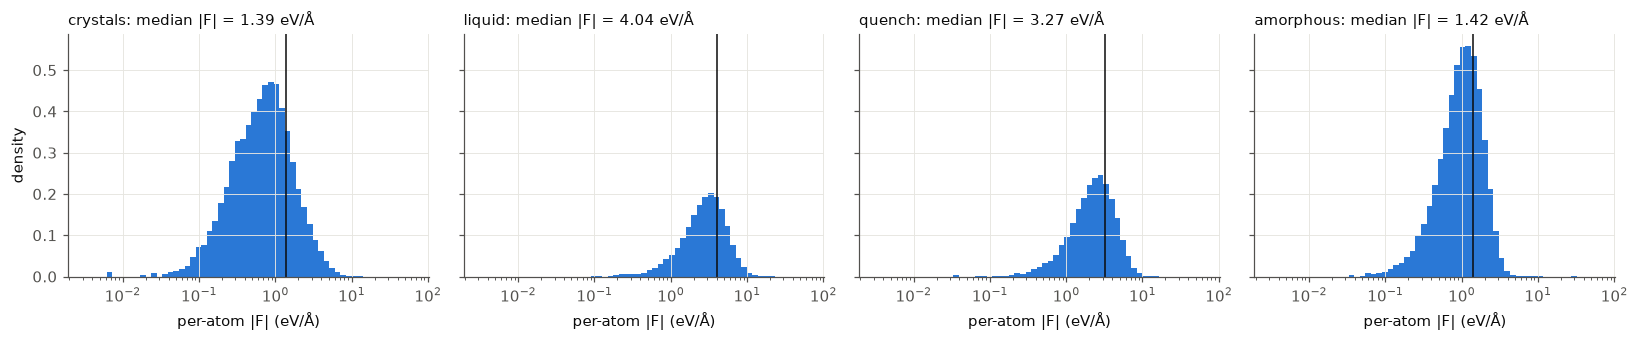

In [6]:
fams = [("crystals", df.config_type.eq("bulk_cryst")), ("liquid", df.config_type.eq("liquid")),
        ("quench", df.config_type.eq("quench")), ("amorphous", df.config_type.eq("bulk_amo"))]
bins = np.logspace(-2.5, 1.8, 60)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (name, m) in zip(axes, fams):
    f = np.concatenate([np.linalg.norm(frames[i].calc.results["forces"], axis=1) for i in df[m].idx])
    ax.hist(f, bins=bins, color=BLUE, density=True)
    ax.set_xscale("log"); ax.axvline(np.median(f), color=INK, lw=1)
    ax.set_title(f"{name}: median |F| = {np.median(f):.2f} eV/Å", fontsize=10, loc="left", color=INK)
    ax.set_xlabel("per-atom |F| (eV/Å)")
axes[0].set_ylabel("density"); plt.tight_layout(); plt.show()

Liquid and quench frames have forces several times larger than the crystals. A single overall force error
would therefore mostly report how well a model does on hot liquid. That is why the benchmark reports
errors **per family**, and why the amorphous column is the one closest to what the team cares about.

## 5. The melt-quench runs come in triplets

The liquid, quench and amorphous frames sit next to each other in the file (indices 700, 701, 702, ...) and share
exactly the same 118 cell volumes. Each triplet looks like three snapshots of one melt-quench run: hot liquid,
mid-quench, and final glass. Below is the Si-O radial distribution of one run at glass-like density, plus the
average number of O around each Si.

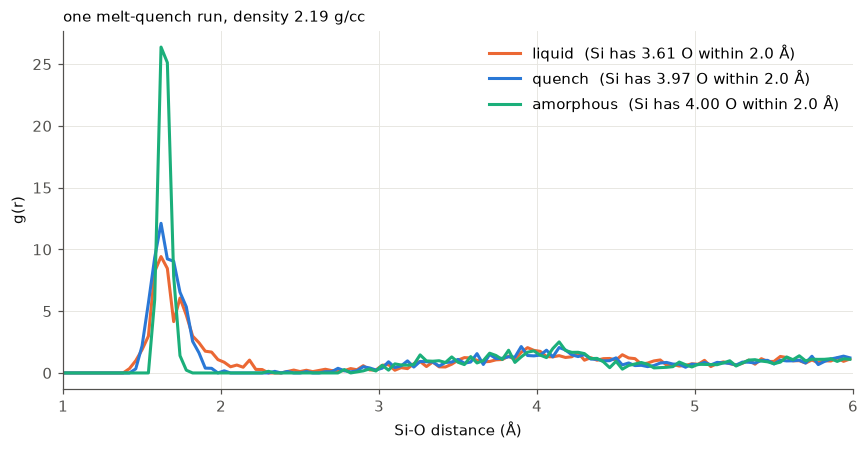

In [7]:
mq = df[df.config_type.isin(["liquid", "quench", "bulk_amo"])]
vol = mq[mq.config_type.eq("bulk_amo")].iloc[(mq[mq.config_type.eq("bulk_amo")].density - 2.2).abs().argmin()].volume
trip = mq[np.isclose(mq.volume, vol)].sort_values("idx").groupby("config_type").first().reset_index()
fig, ax = plt.subplots(figsize=(8, 4.2))
for ct, c, lab in [("liquid", ORANGE, "liquid"), ("quench", BLUE, "quench"), ("bulk_amo", AQUA, "amorphous")]:
    a = frames[int(trip[trip.config_type == ct].idx.iloc[0])]
    g, r = get_rdf(a, rmax=6.0, nbins=150, elements=(14, 8))
    i, j = neighbor_list("ij", a, 2.0)
    si = np.array(a.get_chemical_symbols()) == "Si"
    cn = np.mean([np.sum(~si[j[i == k]]) for k in np.where(si)[0]])
    ax.plot(r, g, color=c, lw=2, label=f"{lab}  (Si has {cn:.2f} O within 2.0 Å)")
ax.set_xlabel("Si-O distance (Å)"); ax.set_ylabel("g(r)"); ax.set_xlim(1, 6)
ax.legend(frameon=False); ax.set_title(f"one melt-quench run, density {trip.density.iloc[0]:.2f} g/cc", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

The liquid peak is broad and some Si have 3 or 5 oxygens. The glass peak is sharp and Si is almost always 4-coordinated:
the SiO4 tetrahedra we built in stage 3 have formed.

**Why this matters for the split.** The three frames of one run share a cell and a history. If the liquid frame
of a run sits in training and its glass sits in the test set, the test is easier than it looks. So the split keeps
each run on one side. Because a few volumes repeat across runs, the split groups by volume, which is slightly stricter
than needed and never leaks.

## 6. Two data gotchas

**Stress sign.** The file stores both `stress` and `virials`, and they have the *same* sign (virial = stress × volume).
Normally virial = −stress × volume, so one of them uses an unusual convention. To find out which, compare the pressure
from the stress tensor with the pressure from the slope of energy against volume, P = −dE/dV, across the strained crystals.

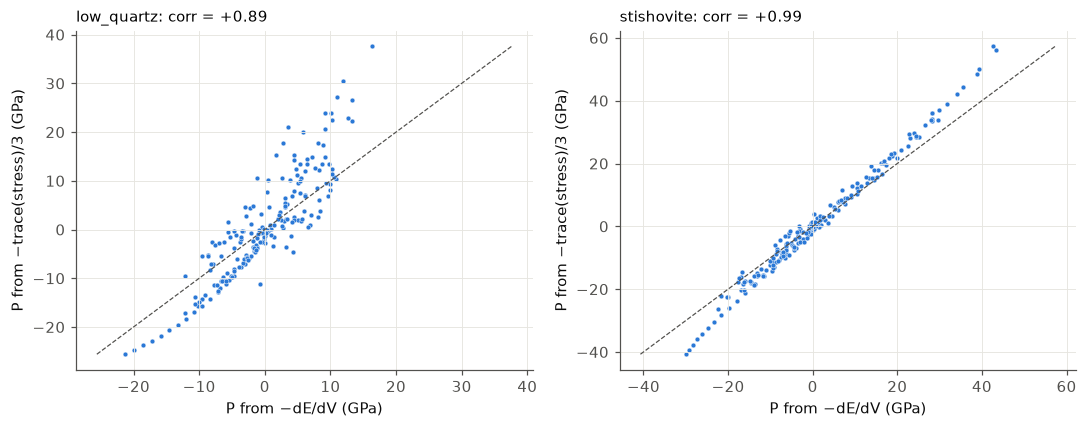

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, ph in zip(axes, ["low_quartz", "stishovite"]):
    s = df[df.family == ph]
    v, e = s.volume / s.natoms, s.e_per_atom
    p_fit = -np.polyval(np.polyder(np.polyfit(v, e, 3)), v) * 160.2177
    ax.scatter(p_fit, s.pressure_gpa, s=10, color=BLUE, edgecolors="white", linewidths=0.3)
    lim = [min(p_fit.min(), s.pressure_gpa.min()), max(p_fit.max(), s.pressure_gpa.max())]
    ax.plot(lim, lim, color=MUTED, lw=0.8, ls="--")
    ax.set_title(f"{ph}: corr = {np.corrcoef(p_fit, s.pressure_gpa)[0, 1]:+.2f}", loc="left", fontsize=10)
    ax.set_xlabel("P from −dE/dV (GPa)"); ax.set_ylabel("P from −trace(stress)/3 (GPa)")
plt.tight_layout(); plt.show()

The two pressures rise together (positive correlation), so **`stress` uses the normal ASE convention** and is what we
train on. With the opposite convention the points would run downhill. They don't sit exactly on the diagonal because
the frames also have rattled atoms and shear strains, which a simple energy-against-volume fit ignores; the sign is what we needed.
`virials` is ignored.

**Reference energies.** The file contains one isolated Si atom and one isolated O atom. MACE uses these as per-element
reference energies (called E0s): the network only has to learn the energy relative to free atoms.

In [9]:
E0 = {a.get_chemical_symbols()[0]: float(a.calc.results["energy"]) for a in frames if len(a) == 1}
print("isolated-atom energies (eV):", E0)
eq = df[df.family == "low_quartz"].e_per_atom.min()
print(f"quartz binding energy from these: {eq - (E0['Si'] + 2 * E0['O']) / 3:.2f} eV/atom  (experiment: about -6.4)")

isolated-atom energies (eV): {'O': -0.66320916, 'Si': -4.06855316}
quartz binding energy from these: -8.75 eV/atom  (experiment: about -6.4)


That number is too large in magnitude. The likely reason is that the free atoms were computed without spin
polarisation, so they sit too high in energy. For training this is harmless: the reference is just a constant per
element, and every model in the benchmark uses the same one.

It does matter for MACE-MP-0's zero-data point. The foundation model was trained on PBE data with its own reference
energies, so out of the box its SCAN total energies will be off by a near-constant amount per element. Comparing
untouched MACE-MP-0 *energies* to this data would look terrible for a boring reason. Its *forces* are a fair comparison.

## 7. Freezing the split

Decisions:

- **Isolated atoms**: used only as reference energies, not as training or test structures.
- **Dimers and small clusters** (133 structures): left out of both the test set and the learning-curve subsets for now.
  They teach short-range repulsion, which matters for MD, but at small training sizes they would swamp the count
  ("10 structures" could be 10 dimers). They can be added back as an always-included extra later.
- **Test set**: 15% of each crystal phase, chosen at random, plus 15% of the melt-quench runs (grouped by volume, as above).
  Fixed seed, saved to disk, never trained on.
- **Training pool**: everything else. For the learning curve, each seed shuffles the pool once and the first N structures
  form the subset, so the subsets are nested (the 30-structure set contains the 10-structure set).

In [10]:
rng = np.random.default_rng(0)
TEST_FRAC = 0.15
bulk = df[~df.config_type.eq("cluster")].copy()
bulk["group"] = np.where(bulk.config_type.eq("bulk_cryst"), "x" + bulk.idx.astype(str),
                         "mq-" + bulk.volume.round(1).astype(str))
test_idx = []
for fam, s in bulk[bulk.config_type.eq("bulk_cryst")].groupby("family"):
    test_idx += list(rng.choice(s.idx.values, size=round(TEST_FRAC * len(s)), replace=False))
mq_groups = np.array(sorted(bulk[~bulk.config_type.eq("bulk_cryst")].group.unique()))
test_groups = set(rng.choice(mq_groups, size=round(TEST_FRAC * len(mq_groups)), replace=False))
test_idx += list(bulk[bulk.group.isin(test_groups)].idx)
test_idx = sorted(int(i) for i in test_idx)
pool_idx = sorted(int(i) for i in bulk.idx if i not in set(test_idx))
assert not set(bulk.set_index("idx").loc[test_idx].group) & set(bulk.set_index("idx").loc[pool_idx].group), "group leak"

SIZES = [10, 30, 100, 300, 1000, len(pool_idx)]
orders = {str(seed): [int(i) for i in np.random.default_rng(100 + seed).permutation(pool_idx)] for seed in range(3)}
bulk["split"] = np.where(bulk.idx.isin(test_idx), "test", "pool")
print(f"test: {len(test_idx)} structures, {bulk[bulk.split == 'test'].natoms.sum():,} atoms | "
      f"pool: {len(pool_idx)} structures, {bulk[bulk.split == 'pool'].natoms.sum():,} atoms")
print("learning-curve sizes:", SIZES)
bulk.pivot_table(index="family", columns="split", values="idx", aggfunc="size", fill_value=0).sort_values("pool")

test: 444 structures, 40,773 atoms | pool: 2495 structures, 227,015 atoms
learning-curve sizes: [10, 30, 100, 300, 1000, 2495]


split,pool,test
family,,
Si-diamond,85,15
beta_cristobalite,85,15
beta_quartz,85,15
beta_tridymite,85,15
tridymite_P212121,85,15
tridymite_C2221,85,15
coesite,170,30
chabazite,170,30
moganite,170,30


How many atoms does "N structures" really mean? Because crystal frames are small and disordered frames are large,
the same N gives very different amounts of force data depending on the draw. The three seeds bracket that spread.

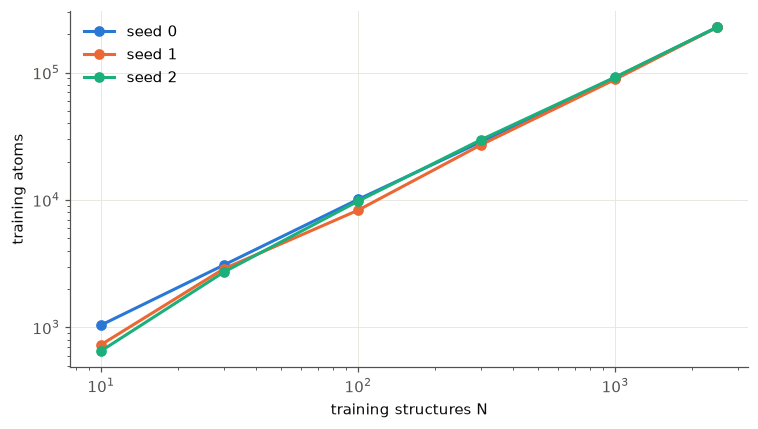

N=  10: fraction disordered (192-atom) frames per seed = [0.5, 0.2, 0.2]
N=  30: fraction disordered (192-atom) frames per seed = [0.4, 0.33, 0.3]
N= 100: fraction disordered (192-atom) frames per seed = [0.37, 0.26, 0.35]


In [11]:
natoms = bulk.set_index("idx").natoms
fig, ax = plt.subplots(figsize=(7, 4))
for seed, c in zip(orders, [BLUE, ORANGE, AQUA]):
    o = orders[seed]
    ax.plot(SIZES, [natoms.loc[o[:n]].sum() for n in SIZES], marker="o", ms=6, lw=2, color=c, label=f"seed {seed}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("training structures N"); ax.set_ylabel("training atoms")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
for n in SIZES[:3]:
    print(f"N={n:>4}: fraction disordered (192-atom) frames per seed =",
          [round(float((natoms.loc[orders[s][:n]] == 192).mean()), 2) for s in orders])

In [12]:
def to_ref(a, i):
    # MACE-style labels: REF_ keys avoid ASE's calculator juggling and name the source explicitly
    b = a.copy(); r = a.calc.results
    stress = r["stress"].reshape(3, 3) if r["stress"].size == 9 else voigt_6_to_full_3x3_stress(r["stress"])
    b.calc = None; b.info = {"REF_energy": float(r["energy"]), "REF_stress": stress,
                             "config_type": a.info["config_type"], "family": family(a), "orig_index": i}
    b.arrays["REF_forces"] = r["forces"].copy()
    return b

(OUT / "data" / "splits").mkdir(parents=True, exist_ok=True)
write(OUT / "data" / "splits" / "test.xyz", [to_ref(frames[i], i) for i in test_idx], format="extxyz")
write(OUT / "data" / "splits" / "pool.xyz", [to_ref(frames[i], i) for i in pool_idx], format="extxyz")
iso = []
for a in frames:
    if len(a) == 1:
        b = a.copy(); b.calc = None
        b.info = {"REF_energy": float(a.calc.results["energy"]), "config_type": "IsolatedAtom"}
        iso.append(b)
write(OUT / "data" / "splits" / "isolated_atoms.xyz", iso, format="extxyz")

split = {"source": "Zenodo 6353684, database/dataset.scan.2.xyz", "test_frac": TEST_FRAC, "split_seed": 0,
         "E0_eV": E0, "test": test_idx, "pool": pool_idx, "sizes": SIZES, "orders": orders,
         "note": "indices are positions in the original file; clusters/dimers excluded; melt-quench grouped by cell volume"}
(OUT / "split_v1.json").write_text(json.dumps(split))
chk = read(OUT / "data" / "splits" / "test.xyz", index=":")
print(len(chk), "test structures written; first REF_energy", chk[0].info["REF_energy"],
      "| matches source:", np.isclose(chk[0].info["REF_energy"], frames[test_idx[0]].calc.results["energy"]))

444 test structures written; first REF_energy -1136.19683342 | matches source: True


## Recap

- **The data.** 3,074 SCAN structures: 13 crystal phases strained and rattled, 118 melt-quench runs
  (liquid, quench, glass at 2.0 to 3.0 g/cc), plus dimers and isolated atoms.
- **Structures are not equal.** Crystals have 6 to 144 atoms, disordered frames 192, so report atoms as well as structures.
- **Forces differ a lot by family.** Liquid forces are several times crystal forces, so errors are reported per family.
- **Melt-quench frames come in triplets from one run.** The split keeps each run on one side.
- **Use `stress`, not `virials`.** It follows the ASE convention.
- **Isolated-atom energies become MACE's reference energies.** Compare untouched MACE-MP-0 on forces, not raw energies (PBE vs SCAN).
- **Frozen outputs.** `silica-benchmark/split_v1.json` (tracked), plus `test.xyz`, `pool.xyz` and `isolated_atoms.xyz`
  under `silica-benchmark/data/splits/` (regenerable, ignored).

Next: a separate environment for MACE (mace-torch pins e3nn 0.4.4, nequip needs 0.6), then the untouched MACE-MP-0
evaluated on the test set as the first point on the plot.